## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Shravya Etta

**Date:** 10/13/2026

**QUESTION 1**

In [15]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

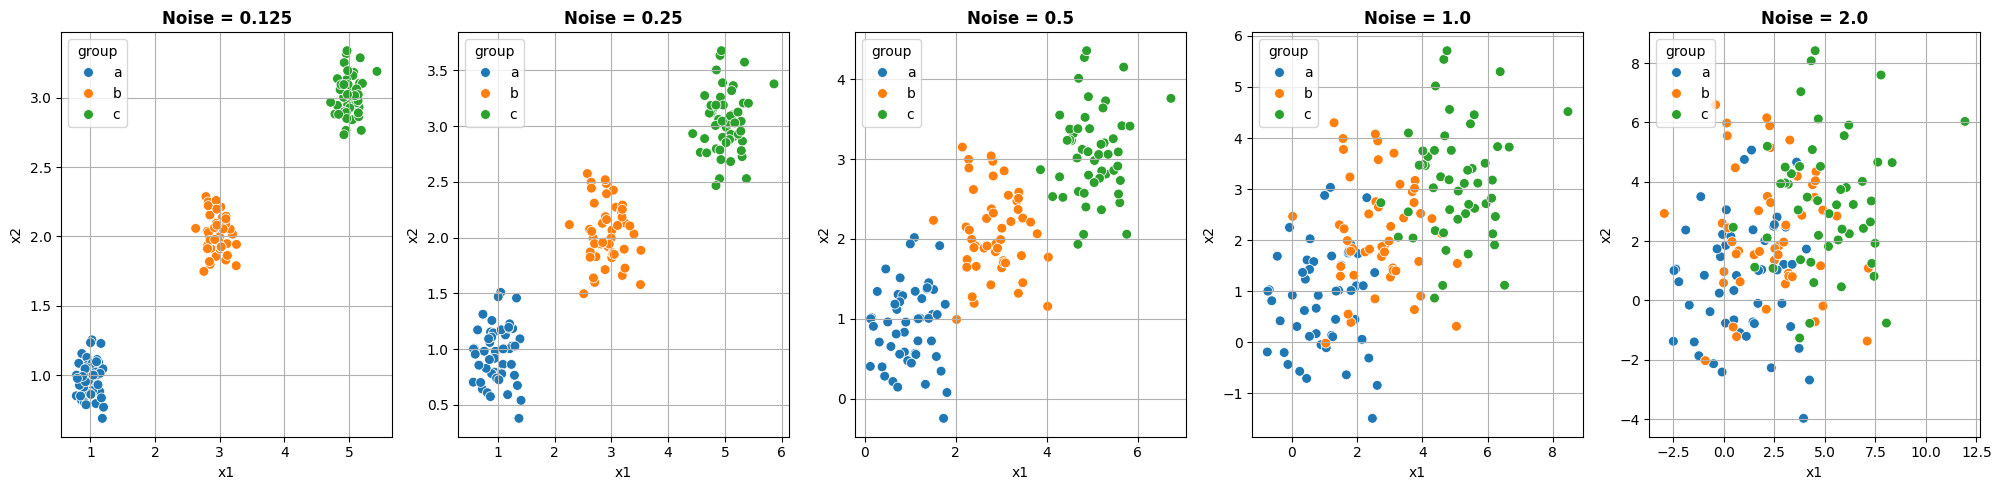

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

datasets = [
    ("Noise = 0.125", df0_125),
    ("Noise = 0.25", df0_25),
    ("Noise = 0.5", df0_5),
    ("Noise = 1.0", df1_0),
    ("Noise = 2.0", df2_0),
]

fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharex=False, sharey=False)

for ax, (title, df) in zip(axes, datasets):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', s=50, ax=ax)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True)

plt.tight_layout()
plt.show()

As noise increases from 0.125 to 2.0, there is increasingly less distinctness between clusters. The clusters are mostly distinct with noise levels of 0.125-0.25, still partially separated with a noise of 0.5, and interdispersed with noise levels of 1 and greater.

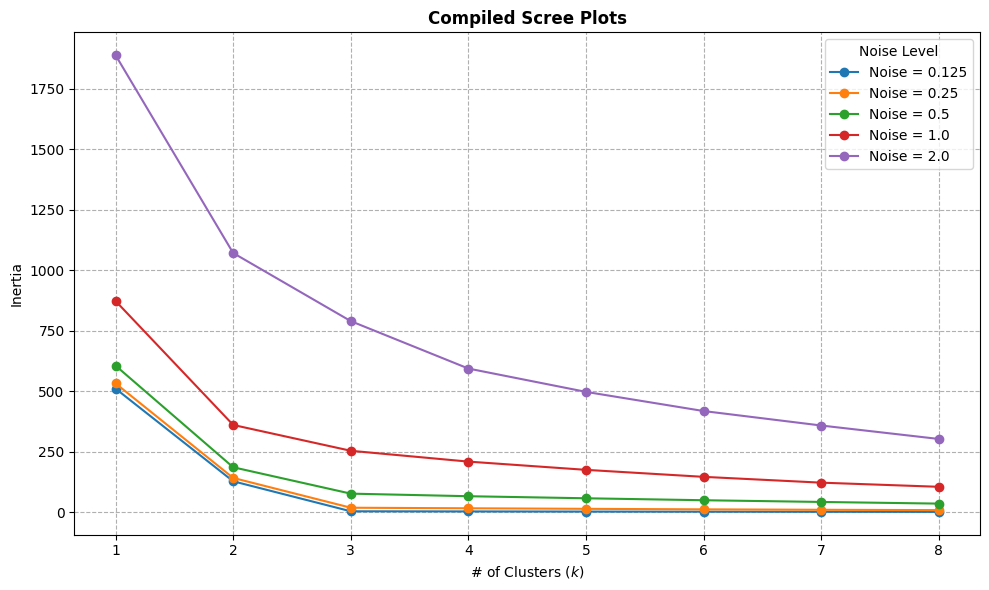

In [ ]:
inertia_results = {}

for label, df in datasets:
    X = df[['x1', 'x2']]
    inertias = []
    for k in range(1, 9):
        km = KMeans(n_clusters=k, random_state=100, n_init=10)
        km.fit(X)
        inertias.append(km.inertia_)
    inertia_results[label] = inertias

plt.figure(figsize=(10, 6))
for label, inertias in inertia_results.items():
    plt.plot(list(range(1, 9)), inertias, marker='o', label=label)

plt.title("Compiled Scree Plots", fontweight='bold')
plt.xlabel("# of Clusters ($k$)")
plt.ylabel("Inertia")
plt.xticks(list(range(1, 9)))
plt.grid(True, linestyle='--')
plt.legend(title="Noise Level")
plt.tight_layout()
plt.show()

At lower noise levels of 0.125-0.5, inertia drops significantly from cluster to cluster, almost leveling off to 0 by k = 3. At higher noise levels, the drop in intertia is more gradual. Hence, for noise levels less than 0.5, identifying the true value of k = 3 is more straightforward because of the presence of a distinct bend in the curve, while choosing a k value is harder and more unreliable with higher noise levels.

The elbow represents the point of peak efficiency in terms of variance. Before the elbow, increasing the number of clusters results in more centroids to separate clusters. At the elbow, each cluster has it's own centroid. After the elbow, adding more clusters takes away from the already formed clusters. When noise is low, the boundary between capturing real structure and splitting existing clusters is more clear.

**QUESTION 2**

In [46]:
df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df.columns = df.columns.str.strip()

# will use this for parts 2-4 to show country on plot
country_col = [col for col in df.columns if 'country' in col.lower()][0]

df_2020 = df[df['Year'] == 2020].dropna().copy()
print(f"# of countries: {len(df_2020)}")

# of countries: 148


In [47]:
df_2020.head() # checking to see if more cleaning is needed

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731


Based on the output above, I concluded that no further cleaning is required.

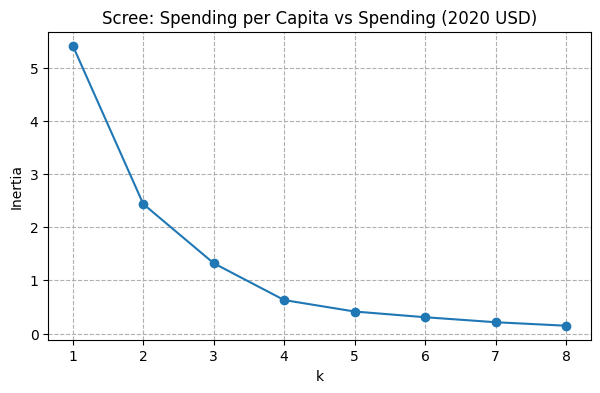

cluster_p2                             0             1              2
Spending (2020 USD) count     126.000000     21.000000       1.000000
                    mean     5943.346303  19975.991473  778397.200000
                    std     24858.961064  21749.736747            NaN
                    min         8.622460    405.790494  778397.200000
                    25%       162.761743   4980.428135  778397.200000
                    50%       580.758315   7269.880030  778397.200000
                    75%      3225.333414  27300.894701  778397.200000
                    max    257973.429834  64558.400000  778397.200000
Spending per Capita count     126.000000     21.000000       1.000000
                    mean      122.034996   1046.433509    2351.631858
                    std       140.041183    501.631845            NaN
                    min         0.580129    616.854430    2351.631858
                    25%        18.505805    737.690186    2351.631858
                    

In [48]:
from sklearn.preprocessing import MinMaxScaler
import plotly.express as px

features_p2 = ['Spending (2020 USD)', 'Spending per Capita']

scaler_p2 = MinMaxScaler()
X_p2norm = scaler_p2.fit_transform(df_2020[features_p2])

# scree plot
inertias_p2 = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_p2norm).inertia_ for k in range(1, 9)]

plt.figure(figsize=(7, 4))
plt.plot(range(1, 9), inertias_p2, marker='o')
plt.title("Scree: Spending per Capita vs Spending (2020 USD)")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.grid(True, linestyle='--')
plt.show()

kmeans_p2 = KMeans(n_clusters=3, random_state=42, n_init=10)
df_2020['cluster_p2'] = kmeans_p2.fit_predict(X_p2norm).astype(str)

# scatter plot
fig_p2 = px.scatter(
    df_2020,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    color='cluster_p2',
    hover_name=country_col,
    hover_data={
        'Spending (2020 USD)': ':$,.0f',
        'Spending per Capita': ':$,.2f',
        'cluster_p2': True
    },
    title="<b>Spending per Capita vs Spending (2020 USD) </b>",
    labels={'cluster_p2': 'Cluster'},
    template='plotly_white'
)

fig_p2.update_traces(marker=dict(size=9, line=dict(width=1)))
fig_p2.show()

print(df_2020.groupby('cluster_p2')[features_p2].describe().T)

The United States is an outlier in total expenditure, with ~778 billion USD in 2020. The US forms it's own cluster because the k-means isolates it as an outlier, despite the fact that it's not the highest per capita spender (ex. the US value of 2,352 USD is below Cluster 1's max value of 2,520 USD). In terms of other cluster patterns, Cluster 0 has lower per capita spending, where the Cluster 0 max is ~541 USD while the Cluster 1 minimum is ~617 USD. These higher per capita values that indicate either wealthy, smaller nations or highly militarized ones with smaller populations.

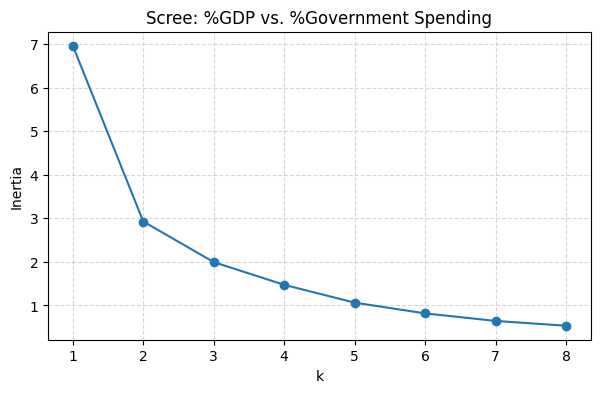

cluster_p3                                    0          1          2
Percent of Government Spending count  39.000000  99.000000  10.000000
                               mean    0.098683   0.035777   0.171289
                               std     0.024125   0.014549   0.058725
                               min     0.059520   0.004896   0.097882
                               25%     0.082430   0.025921   0.135010
                               50%     0.092044   0.034261   0.168248
                               75%     0.112633   0.047402   0.179081
                               max     0.157918   0.074624   0.303027
Percent of GDP                 count  39.000000  99.000000  10.000000
                               mean    0.027412   0.012664   0.058071
                               std     0.008191   0.005681   0.024867
                               min     0.011317   0.000054   0.011742
                               25%     0.021254   0.008393   0.049297
                    

In [49]:
features_p3 = ['Percent of Government Spending', 'Percent of GDP']

scaler_p3 = MinMaxScaler()
X_p3norm = scaler_p3.fit_transform(df_2020[features_p3])

inertias_p3 = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_p3norm).inertia_ for k in range(1, 9)]

plt.figure(figsize=(7, 4))
plt.plot(range(1, 9), inertias_p3, marker='o')
plt.title("Scree: %GDP vs. %Government Spending")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

kmeans_p3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df_2020['cluster_p3'] = kmeans_p3.fit_predict(X_p3norm).astype(str)

# scatter plot
fig_p3 = px.scatter(
    df_2020,
    x='Percent of Government Spending',
    y='Percent of GDP',
    color='cluster_p3',
    hover_name=country_col,
    hover_data={
        'Percent of Government Spending': ':.2f',
        'Percent of GDP': ':.2f',
        'cluster_p3': True
    },
    title="<b>%GDP (2020) vs. %Government Spending</b>",
    labels={'cluster_p3': 'Cluster'},
    template='plotly_white'
)

fig_p3.update_traces(marker=dict(size=9, line=dict(width=1)))
fig_p3.show()

print(df_2020.groupby('cluster_p3')[features_p3].describe().T)

Compared to the previous part, the data doesn't separate into a cluster of points and an outlier because, unlike dollar values, GDP and government spending percentages are bounded values (ex. the US defense budget was ~3.7% of GDP and ~10%–11% of federal spending in 2020). Additionally, nations in the highest cluster are those that prioritize defense spending whilst being prone to regional instability, such as Oman and Saudi Arabia.

In [50]:
features_all = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP',
]

scaler_all = MinMaxScaler()
X_all_norm = scaler_all.fit_transform(df_2020[features_all])

kmeans_all = KMeans(n_clusters=4, random_state=42, n_init=10)
df_2020['cluster_all'] = kmeans_all.fit_predict(X_all_norm).astype(str)

fig_all = px.scatter(
    df_2020,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    size='Percent of GDP',  # point size is % of GDP
    color='cluster_all',
    hover_name=country_col,
    log_x=True,  # scales x-axis so that the US outlier doesn't imapct graph
    hover_data={
        'Spending (2020 USD)': ':$,.0f',
        'Spending per Capita': ':$,.2f',
        'Percent of Government Spending': ':.2f',
        'Percent of GDP': ':.2f',
        'cluster_all': True,
    },
    title='<b>4-Feature K-Means Clustering (Point Size = % of GDP)</b>',
    labels={
        'cluster_all': 'Cluster',
        'Spending (2020 USD)': 'Spending (2020 USD)',
    },
    template='plotly_white',
)

fig_all.update_traces(marker=dict(line=dict(width=1), sizemin=4))

fig_all.show()
print(df_2020.groupby('cluster_all')[features_all].mean())

             Spending (2020 USD)  Spending per Capita  \
cluster_all                                             
0                    4513.543790            70.290644   
1                  147964.582042          1875.150751   
2                   15330.618681           612.677541   
3                    9073.543709           215.920971   

             Percent of Government Spending  Percent of GDP  
cluster_all                                                  
0                                  0.043199        0.012481  
1                                  0.135351        0.062634  
2                                  0.033280        0.016585  
3                                  0.123701        0.034105  


Looking at the graph above, the US is once again an outlier because of the difference in magnitude of it's total budget as well as high per capita spending. In order to ensure this outlier didn't inhibit the readability of the data for the rest of the countries, I log-scaled the x-axis.

Once again, militarized nations with high risk of regional conflict like Saudia Arabia, Isreal, and Oman also stand out with high per capita spending, high % of GDP, and high % of government budget. Meanwhile, affluent and low risk of regional burden nations like many European and East Asian countries have moderate per capita spending with low percentage burdens of 1%–2% of GDP. Lastly, developing nations demonstrate low spending across all four of the metrics.

The k-means algorithm did reveal useful patterns but had some caveats. It succeeded in the way it separated countries since looking at dollar amounts alone only identifies nations with high GDPs, while combining per capita and percentage metrics allows us to identify which nations allocate a high share of their domestic resources toward defense. However, a limitation is that typical k-means (ie. without the log-scaling I added) and min-max scaling results in compressing over 90% of the nations in the dataset to a narrow range near zero due to the US outlier. The log scaling helps produce a more readable graoh.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** d8db9c3eb77716640386a22feba704b448c57a19
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. Referencing my solution in Phase 1 of this assignment, write in a numbered list corrections I could make.
2. [Paste follow-up prompt]

### *AI-proposed changes


**Question 1**

1. **Put the scree curves on a scale where the low-noise elbows are visible.** Inertia at noise 2.0 is roughly 600, while at 0.125 it is under 10, so the low-noise curves look flat along the bottom of your combined plot. You can't see the elbow you describe. Use a log y-axis, separate subplots, or normalize each curve by its k=1 inertia.

2. **Fix the claim that inertia levels off "to 0 by k = 3."** Inertia never reaches 0. At noise 0.5 it is around 75, and the real point is that the drop becomes small after k=3 compared with the drops before it.

3. **Rewrite the elbow explanation around what inertia actually measures.** Inertia is the within-cluster sum of squared distances to the centroid. From k=1→2→3, each new centroid separates two real groups, so inertia drops sharply. After k=3, each new centroid only splits a group that is already one cluster, so it removes only noise-sized variation. Your line "each cluster has its own centroid" is the right idea, but "peak efficiency in terms of variance" and "takes away from already formed clusters" are vague. Tie the explanation to the a/b/c groups in the simulation.

4. **Consider sharing axes (or at least the same limits) across the five scatterplots** so the growth in spread is directly comparable. Also fix the typos: "intertia" and "it's own" should be "inertia" and "its own."

**Question 2**

5. **Fix the `NameError` in the scree plot.** You define `X_p2norm` but call `X_p2_norm`. Rename one so the cell runs top to bottom on a fresh kernel. While you're there, make the naming consistent (`k_optp2` vs. `kmeans_p2`) and use the same `random_state` as in Q1.

6. **Load the file from the right path.** The assignment says the CSV is in `./data`, but you call `pd.read_csv('SIPRI Military Expenditure Database.csv')` directly. Use `./data/SIPRI Military Expenditure Database.csv`.

7. **Actually check the data cleaning question.** Looking at `.head()` isn't enough to conclude no cleaning is needed. Run `df_2020.info()` and `.describe()` to check dtypes, impossible values, and duplicates. Drop the leftover `index` column. Check for non-country rows such as regional totals. Also address units: `Percent of GDP` and `Percent of Government Spending` are stored as fractions (0.0136), not percentages, and the spending variables are on wildly different scales, which is why normalization matters.

8. **Name actual countries in each cluster.** Cluster 1's "wealthy smaller nations or highly militarized ones" is a guess. Print `df_2020.groupby('cluster_p2')['Country'].apply(list)` (or the top few per cluster) and describe the real pattern, such as Gulf states, Israel, and NATO members. Also say which cluster China falls in.

9. **Improve the scatterplot.** Use log scales, or annotate the US, since the raw-scale plot squashes 146 of the 148 points into a corner.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Reject | Same reason as explained below. |
| 2 | Reject | While inertia doesn't reach 0 exactly, the values do drop significantly and level off to a near-zero number. Leaving the scale this way allows for easier and clearer analysis. |
| 3 | Modify | My initial explanation is still true, but I added a clarification of what inertia represents in this case. |
| 4 | Accept | This is not a necessary change but makes the formatting cleaner. |
| 5 | Accept | A naming error I didn't notice. |
| 6 | Reject | The CSV file is already loaded properly. |
| 7 | Accept | I went through a more thorough data checking process following the suggestions Claude made, although it resulted in the same conclusion. |
| 8 | Reject | I already mentioned specific names of some nations. |
| 9 | Reject | I log-scaled the last graph but not the one for part 2 because I felt that the assignment was meant to show that the first method of graphing was not as effective as the second one. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

**QUESTION 1**

In [51]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

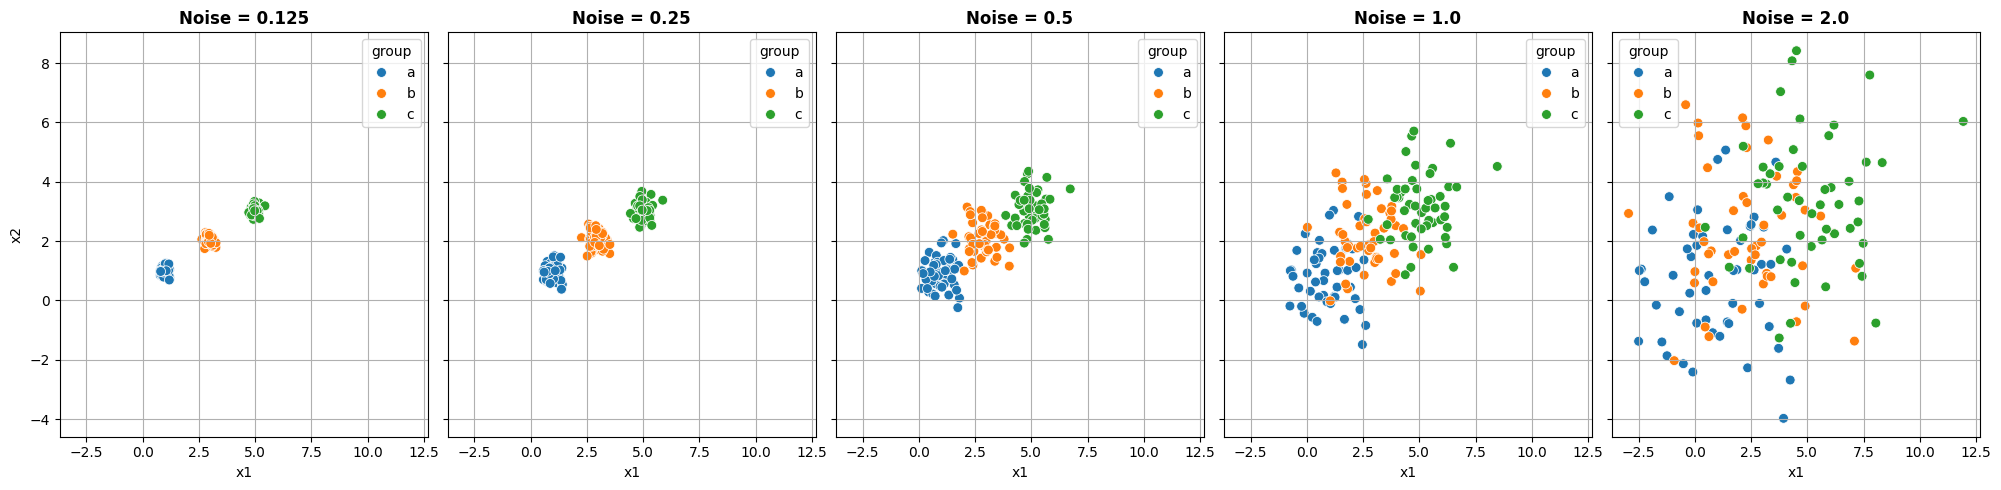

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

datasets = [
    ("Noise = 0.125", df0_125),
    ("Noise = 0.25", df0_25),
    ("Noise = 0.5", df0_5),
    ("Noise = 1.0", df1_0),
    ("Noise = 2.0", df2_0),
]

fig, axes = plt.subplots(1, 5, figsize=(20, 5), sharex=True, sharey=True)
for ax, (title, df) in zip(axes, datasets):
    sns.scatterplot(data=df, x='x1', y='x2', hue='group', s=50, ax=ax)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.grid(True)

plt.tight_layout()
plt.show()

As noise increases from 0.125 to 2.0, there is increasingly less distinctness between clusters. The clusters are mostly distinct with noise levels of 0.125-0.25, still partially separated with a noise of 0.5, and interdispersed with noise levels of 1 and greater.

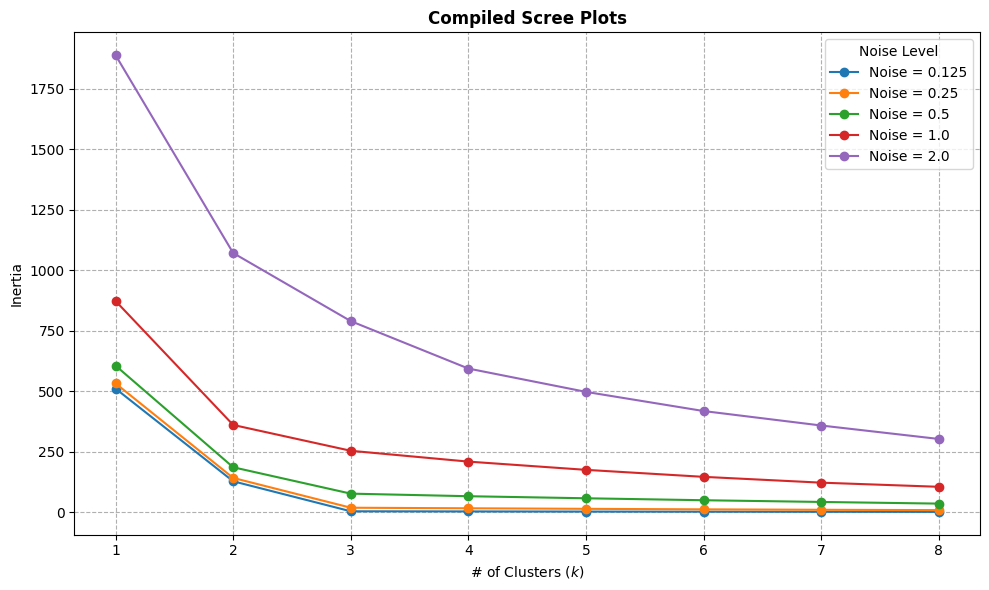

In [53]:
inertia_results = {}

for label, df in datasets:
    X = df[['x1', 'x2']]
    inertias = []
    for k in range(1, 9):
        km = KMeans(n_clusters=k, random_state=100, n_init=10)
        km.fit(X)
        inertias.append(km.inertia_)
    inertia_results[label] = inertias

plt.figure(figsize=(10, 6))
for label, inertias in inertia_results.items():
    plt.plot(list(range(1, 9)), inertias, marker='o', label=label)

plt.title("Compiled Scree Plots", fontweight='bold')
plt.xlabel("# of Clusters ($k$)")
plt.ylabel("Inertia")
plt.xticks(list(range(1, 9)))
plt.grid(True, linestyle='--')
plt.legend(title="Noise Level")
plt.tight_layout()
plt.show()

At lower noise levels of 0.125-0.5, inertia drops significantly from cluster to cluster, almost leveling off to 0 by k = 3. At higher noise levels, the drop in intertia is more gradual. Since inertia represents the within-cluster sum of squared distances to the centroid, each new centroid separates two real groups as k=1 to k-3, so inertia drops sharply. Hence, for noise levels less than 0.5, identifying the true value of k = 3 is more straightforward because of the presence of a distinct bend in the curve, while choosing a k value is harder and more unreliable with higher noise levels.

The elbow represents the point of peak efficiency in terms of variance. Before the elbow, increasing the number of clusters results in more centroids to separate clusters. At the elbow, each cluster has it's own centroid. After the elbow, adding more clusters takes away from the already formed clusters. When noise is low, the boundary between capturing real structure and splitting existing clusters is more clear.

**QUESTION 2**

In [54]:
df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df.columns = df.columns.str.strip()

# will use this for parts 2-4 to show country on plot
country_col = [col for col in df.columns if 'country' in col.lower()][0]

df_2020 = df[df['Year'] == 2020].dropna().copy()
print(f"# of countries: {len(df_2020)}")

# of countries: 148


In [55]:
num_cols = ['Spending (2020 USD)', 'Percent of GDP',
            'Percent of Government Spending', 'Spending per Capita']

df_2020.info()
print(df_2020[num_cols].describe().T)
print("Duplicate countries:", df_2020['Country'].duplicated().sum())
print("Non-positive values per column:\n", (df_2020[num_cols] <= 0).sum())
print("Percent columns > 1 (would signal mixed units):",
      (df_2020[['Percent of GDP', 'Percent of Government Spending']] > 1).sum().to_dict())
print(sorted(df_2020['Country']))

<class 'pandas.core.frame.DataFrame'>
Index: 148 entries, 32 to 5880
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   index                           148 non-null    int64  
 1   Year                            148 non-null    int64  
 2   Country                         148 non-null    object 
 3   Spending (2020 USD)             148 non-null    float64
 4   Percent of GDP                  148 non-null    float64
 5   Percent of Government Spending  148 non-null    float64
 6   Spending per Capita             148 non-null    float64
dtypes: float64(4), int64(2), object(1)
memory usage: 9.2+ KB
                                count          mean           std       min  \
Spending (2020 USD)             148.0  13153.747670  68005.236120  8.622460   
Percent of GDP                  148.0      0.019619      0.015033  0.000054   
Percent of Government Spending  148.0      0.061510

Based on the output above, I concluded that no further cleaning is required.

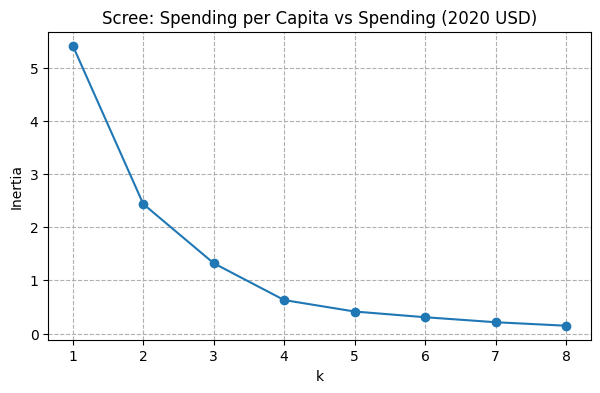

cluster_p2                             0             1              2
Spending (2020 USD) count     126.000000     21.000000       1.000000
                    mean     5943.346303  19975.991473  778397.200000
                    std     24858.961064  21749.736747            NaN
                    min         8.622460    405.790494  778397.200000
                    25%       162.761743   4980.428135  778397.200000
                    50%       580.758315   7269.880030  778397.200000
                    75%      3225.333414  27300.894701  778397.200000
                    max    257973.429834  64558.400000  778397.200000
Spending per Capita count     126.000000     21.000000       1.000000
                    mean      122.034996   1046.433509    2351.631858
                    std       140.041183    501.631845            NaN
                    min         0.580129    616.854430    2351.631858
                    25%        18.505805    737.690186    2351.631858
                    

In [56]:
from sklearn.preprocessing import MinMaxScaler
import plotly.express as px

features_p2 = ['Spending (2020 USD)', 'Spending per Capita']

scaler_p2 = MinMaxScaler()
X_p2norm = scaler_p2.fit_transform(df_2020[features_p2])

# scree plot
inertias_p2 = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_p2norm).inertia_ for k in range(1, 9)]

plt.figure(figsize=(7, 4))
plt.plot(range(1, 9), inertias_p2, marker='o')
plt.title("Scree: Spending per Capita vs Spending (2020 USD)")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.grid(True, linestyle='--')
plt.show()

kmeans_p2 = KMeans(n_clusters=3, random_state=42, n_init=10)
df_2020['cluster_p2'] = kmeans_p2.fit_predict(X_p2norm).astype(str)

# scatter plot
fig_p2 = px.scatter(
    df_2020,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    color='cluster_p2',
    hover_name=country_col,
    hover_data={
        'Spending (2020 USD)': ':$,.0f',
        'Spending per Capita': ':$,.2f',
        'cluster_p2': True
    },
    title="<b>Spending per Capita vs Spending (2020 USD) </b>",
    labels={'cluster_p2': 'Cluster'},
    template='plotly_white'
)

fig_p2.update_traces(marker=dict(size=9, line=dict(width=1)))
fig_p2.show()

print(df_2020.groupby('cluster_p2')[features_p2].describe().T)

The United States is an outlier in total expenditure, with ~778 billion USD in 2020. The US forms it's own cluster because the k-means isolates it as an outlier, despite the fact that it's not the highest per capita spender (ex. the US value of 2,352 USD is below Cluster 1's max value of 2,520 USD). In terms of other cluster patterns, Cluster 0 has lower per capita spending, where the Cluster 0 max is ~541 USD while the Cluster 1 minimum is ~617 USD. These higher per capita values that indicate either wealthy, smaller nations or highly militarized ones with smaller populations.

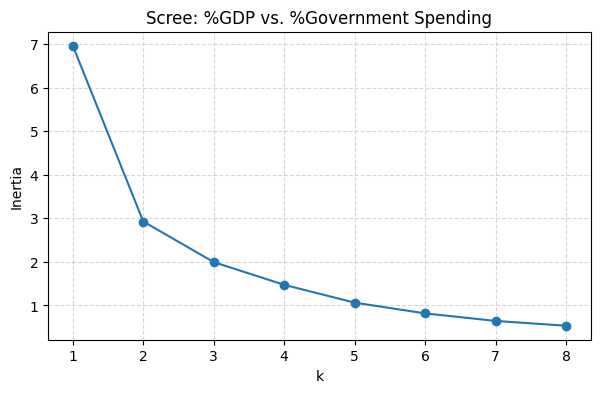

cluster_p3                                    0          1          2
Percent of Government Spending count  39.000000  99.000000  10.000000
                               mean    0.098683   0.035777   0.171289
                               std     0.024125   0.014549   0.058725
                               min     0.059520   0.004896   0.097882
                               25%     0.082430   0.025921   0.135010
                               50%     0.092044   0.034261   0.168248
                               75%     0.112633   0.047402   0.179081
                               max     0.157918   0.074624   0.303027
Percent of GDP                 count  39.000000  99.000000  10.000000
                               mean    0.027412   0.012664   0.058071
                               std     0.008191   0.005681   0.024867
                               min     0.011317   0.000054   0.011742
                               25%     0.021254   0.008393   0.049297
                    

In [57]:
features_p3 = ['Percent of Government Spending', 'Percent of GDP']

scaler_p3 = MinMaxScaler()
X_p3norm = scaler_p3.fit_transform(df_2020[features_p3])

inertias_p3 = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_p3norm).inertia_ for k in range(1, 9)]

plt.figure(figsize=(7, 4))
plt.plot(range(1, 9), inertias_p3, marker='o')
plt.title("Scree: %GDP vs. %Government Spending")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

kmeans_p3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df_2020['cluster_p3'] = kmeans_p3.fit_predict(X_p3norm).astype(str)

# scatter plot
fig_p3 = px.scatter(
    df_2020,
    x='Percent of Government Spending',
    y='Percent of GDP',
    color='cluster_p3',
    hover_name=country_col,
    hover_data={
        'Percent of Government Spending': ':.2f',
        'Percent of GDP': ':.2f',
        'cluster_p3': True
    },
    title="<b>%GDP (2020) vs. %Government Spending</b>",
    labels={'cluster_p3': 'Cluster'},
    template='plotly_white'
)

fig_p3.update_traces(marker=dict(size=9, line=dict(width=1)))
fig_p3.show()

print(df_2020.groupby('cluster_p3')[features_p3].describe().T)

Compared to the previous part, the data doesn't separate into a cluster of points and an outlier because, unlike dollar values, GDP and government spending percentages are bounded values (ex. the US defense budget was ~3.7% of GDP and ~10%–11% of federal spending in 2020). Additionally, nations in the highest cluster are those that prioritize defense spending whilst being prone to regional instability, such as Oman and Saudi Arabia.

In [58]:
features_all = [
    'Spending (2020 USD)',
    'Spending per Capita',
    'Percent of Government Spending',
    'Percent of GDP',
]

scaler_all = MinMaxScaler()
X_all_norm = scaler_all.fit_transform(df_2020[features_all])

kmeans_all = KMeans(n_clusters=4, random_state=42, n_init=10)
df_2020['cluster_all'] = kmeans_all.fit_predict(X_all_norm).astype(str)

fig_all = px.scatter(
    df_2020,
    x='Spending (2020 USD)',
    y='Spending per Capita',
    size='Percent of GDP',  # point size is % of GDP
    color='cluster_all',
    hover_name=country_col,
    log_x=True,  # scales x-axis so that the US outlier doesn't imapct graph
    hover_data={
        'Spending (2020 USD)': ':$,.0f',
        'Spending per Capita': ':$,.2f',
        'Percent of Government Spending': ':.2f',
        'Percent of GDP': ':.2f',
        'cluster_all': True,
    },
    title='<b>4-Feature K-Means Clustering (Point Size = % of GDP)</b>',
    labels={
        'cluster_all': 'Cluster',
        'Spending (2020 USD)': 'Spending (2020 USD)',
    },
    template='plotly_white',
)

fig_all.update_traces(marker=dict(line=dict(width=1), sizemin=4))

fig_all.show()
print(df_2020.groupby('cluster_all')[features_all].mean())

             Spending (2020 USD)  Spending per Capita  \
cluster_all                                             
0                    4513.543790            70.290644   
1                  147964.582042          1875.150751   
2                   15330.618681           612.677541   
3                    9073.543709           215.920971   

             Percent of Government Spending  Percent of GDP  
cluster_all                                                  
0                                  0.043199        0.012481  
1                                  0.135351        0.062634  
2                                  0.033280        0.016585  
3                                  0.123701        0.034105  


Looking at the graph above, the US is once again an outlier because of the difference in magnitude of it's total budget as well as high per capita spending. In order to ensure this outlier didn't inhibit the readability of the data for the rest of the countries, I log-scaled the x-axis.

Once again, militarized nations with high risk of regional conflict like Saudia Arabia, Isreal, and Oman also stand out with high per capita spending, high % of GDP, and high % of government budget. Meanwhile, affluent and low risk of regional burden nations like many European and East Asian countries have moderate per capita spending with low percentage burdens of 1%–2% of GDP. Lastly, developing nations demonstrate low spending across all four of the metrics.

The k-means algorithm did reveal useful patterns but had some caveats. It succeeded in the way it separated countries since looking at dollar amounts alone only identifies nations with high GDPs, while combining per capita and percentage metrics allows us to identify which nations allocate a high share of their domestic resources toward defense. However, a limitation is that typical k-means (ie. without the log-scaling I added) and min-max scaling results in compressing over 90% of the nations in the dataset to a narrow range near zero due to the US outlier. The log scaling helps produce a more readable graoh.

### *Reflection on AI assistance
In your own words without generative AI.

Claude was helpful in parsing through my code and logic in detail and caught some fine errors that I wouldn't have been able to. It was also helpful in making suggestions that would bolster my analysis, for instance by improving the way I checked if the dataset was properly cleaned and better explaining what inertia means in this context.

However, it made quite a few errors in identifying actually valuable changes to my code. Moving forward, I think I should emphasize efficiency and conciseness in my prompt because the main improvements that I think need to be made to my code is conciseness. The suggestions it often gives me makes my work more convoluded. It has also given me a few suggestions of things I have already done in my work.

I feel that while AI is overall a helpful tool, it can tend to over-complicate results if it's not specified in the prompt that additonal analysis is not needed/conciseness is important.